In [1]:
import requests
import csv
from datetime import datetime
from pathlib import Path
import yaml
import os

NAVIDROME_URL = "http://192.168.1.99:4533"
if "__file__" in globals():
    BASE_DIR = Path(__file__).resolve().parent
else:
    BASE_DIR = Path(os.getcwd())

config = {}

local_config = BASE_DIR / "config.local.yaml"

with open(local_config, "r") as f:
    config.update(yaml.safe_load(f) or {})

navidrome_cfg = config.get("navidrome", {})

USER = navidrome_cfg.get("user")
PASSWORD = navidrome_cfg.get("password")

def fetch_navidrome_stats():
    # Autenticación
    # Stats generales
    r2 = requests.get(
        f"{NAVIDROME_URL}/rest/getAlbumList2",
        params={
            "u": USER,
            "p": PASSWORD,
            "v": "1.16.1",
            "c": "stats",
            "f": "json",
            "type": "newest",
            "size": 1
        }
    )
    
#     data = r2.json()['subsonic-response']
#     total_albums = data.get('albumList2', {}).get('album', [])
   
#     # Guardar en CSV con fecha
#     stats_file = Path('.') / 'data' / 'navidrome_stats.csv'
#     file_exists = stats_file.exists()
    
#     with open(stats_file, 'a', newline='') as f:
#         writer = csv.writer(f)
#         if not file_exists:
#             writer.writerow(['date', 'albums', 'tracks'])
#         writer.writerow([datetime.now().strftime('%Y-%m-%d'), len(total_albums), ''])

# if __name__ == "__main__":
#     fetch_navidrome_stats()

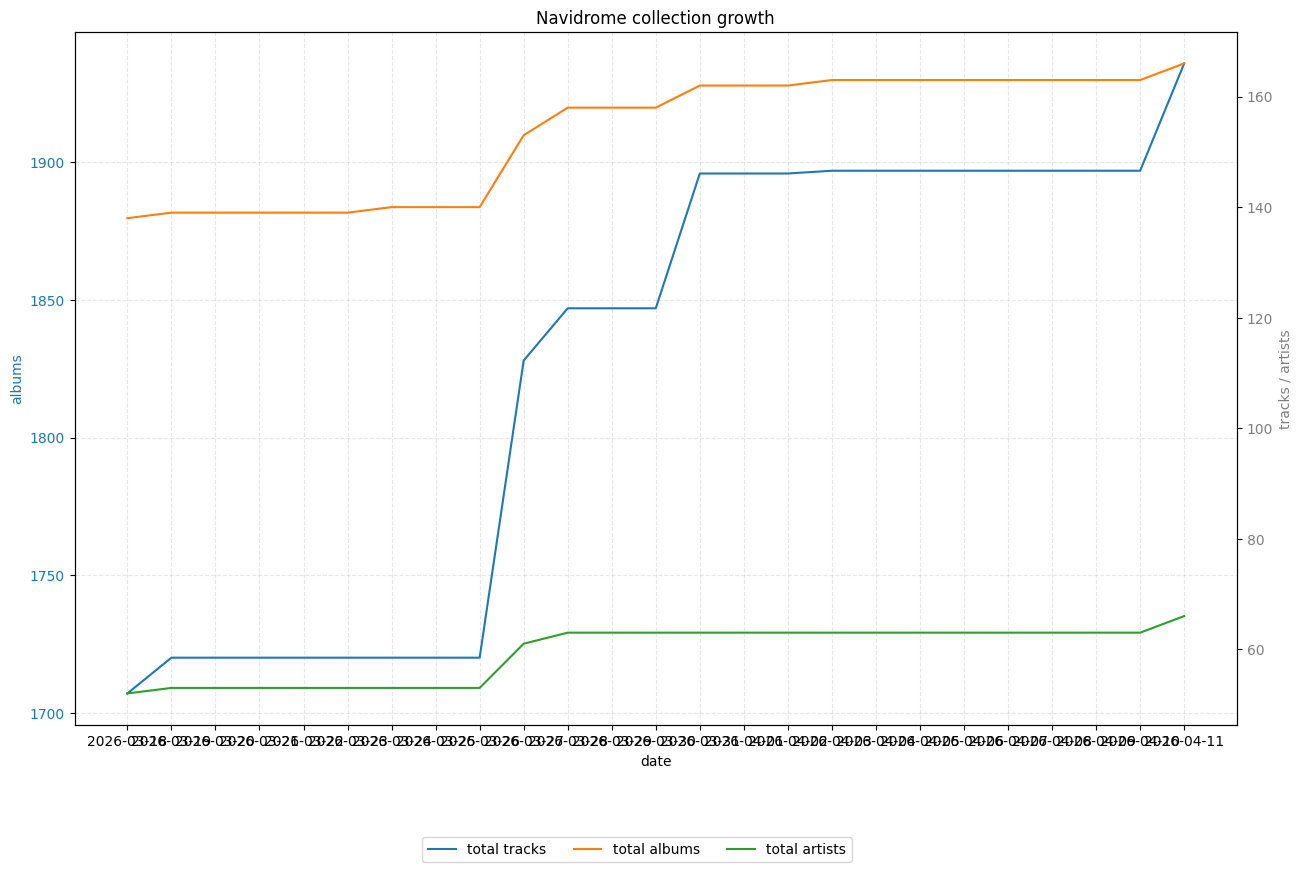

In [2]:
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Leer el archivo CSV
stats_file = Path('.') / 'data' / 'navidrome_stats.csv'
df = pd.read_csv(stats_file)
data = df.values

x = data[:, 0]  # Primera columna
y1 = data[:, 1]  # albums
y2 = data[:, 2]  # tracks
y3 = data[:, 3]  # artists

fig, ax1 = plt.subplots(figsize=(15, 9) )

ax1.plot(x, y2, label='total tracks', color='tab:blue')
ax1.set_xlabel('date')
ax1.set_ylabel('albums', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(x, y1, label='total albums', color='tab:orange')
ax2.plot(x, y3, label='total artists', color='tab:green')
ax2.set_ylabel('tracks / artists', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

fig.legend(loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3)
plt.title('Navidrome collection growth')
plt.show()

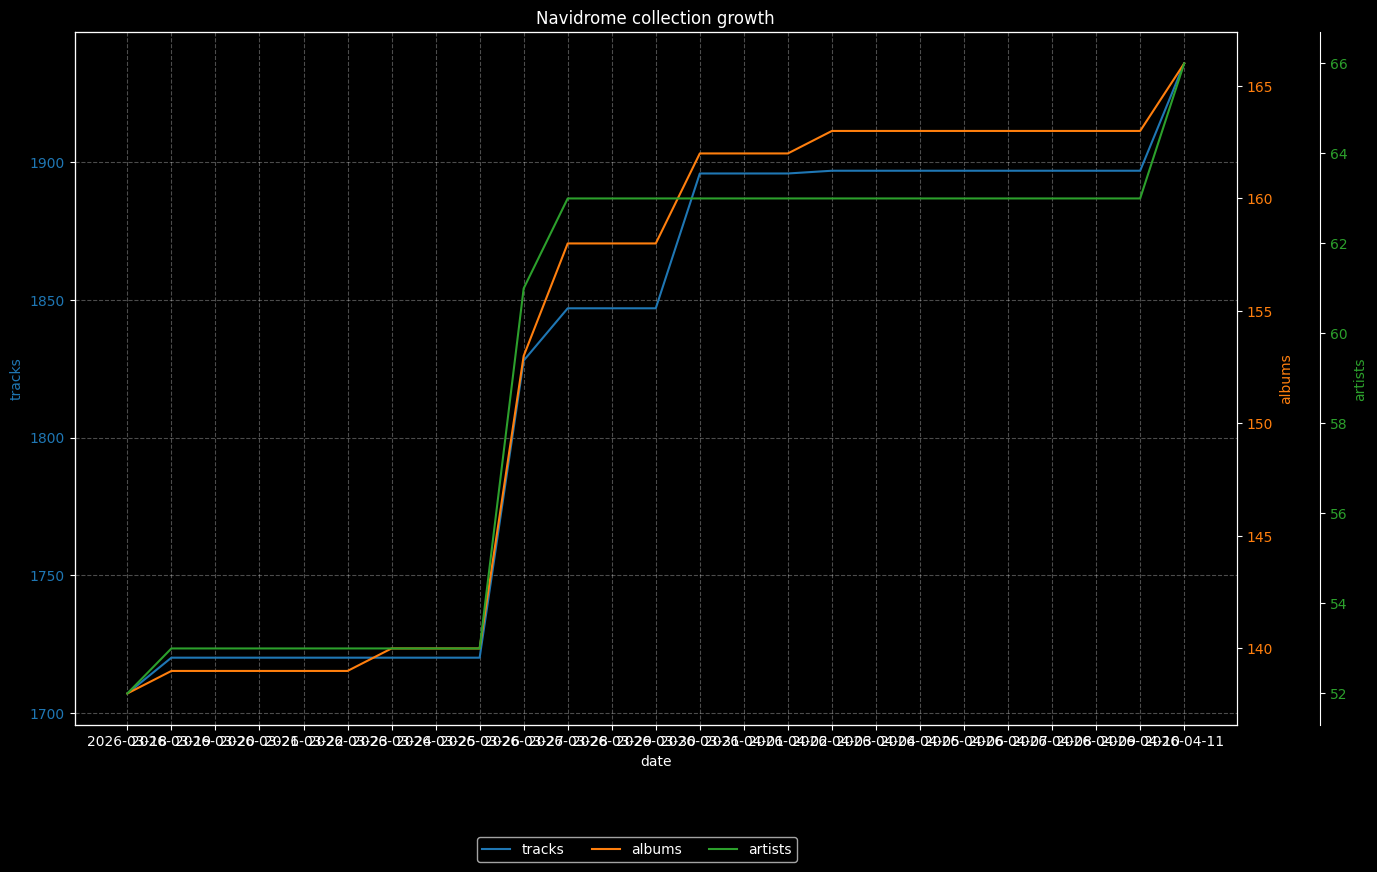

In [5]:
fig, ax1 = plt.subplots(figsize=(15, 9))

# --- EJE 1 (tracks) ---
ax1.plot(x, y2, label='tracks', color='tab:blue')
ax1.set_xlabel('date')
ax1.set_ylabel('tracks', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.3)

# --- EJE 2 (albums) ---
ax2 = ax1.twinx()
ax2.plot(x, y1, label='albums', color='tab:orange')
ax2.set_ylabel('albums', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

# --- EJE 3 (artists) ---
ax3 = ax1.twinx()

# mover el tercer eje un poco a la derecha
ax3.spines["right"].set_position(("outward", 60))

ax3.plot(x, y3, label='artists', color='tab:green')
ax3.set_ylabel('artists', color='tab:green')
ax3.tick_params(axis='y', labelcolor='tab:green')

# --- Leyenda ---
lines = ax1.get_lines() + ax2.get_lines() + ax3.get_lines()
labels = [l.get_label() for l in lines]

fig.legend(lines, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3)

plt.title('Navidrome collection growth')
plt.show()

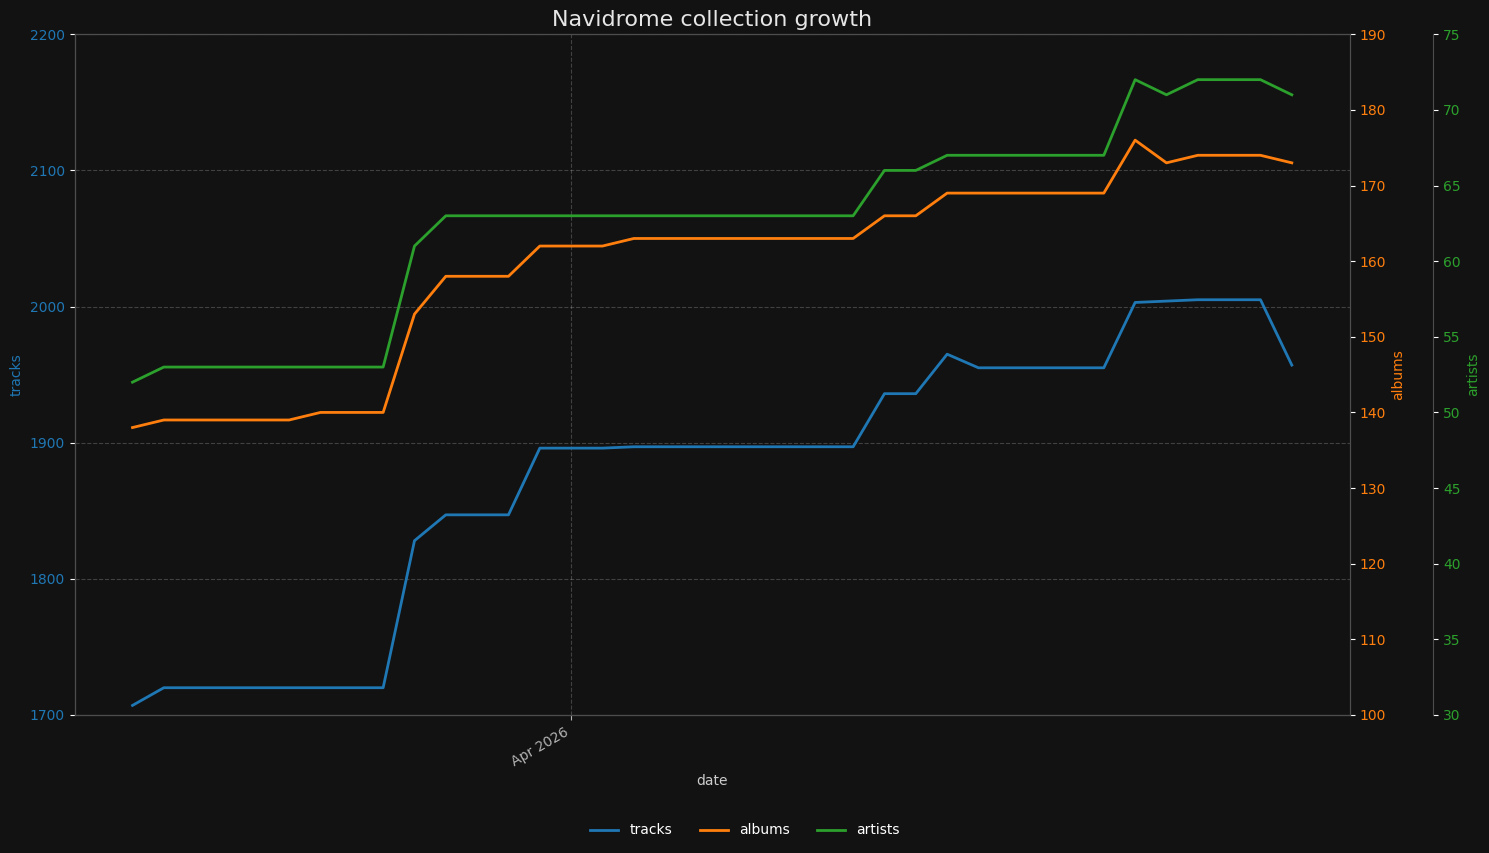

In [1]:
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.dates as mdates

# Leer el archivo CSV
stats_file = Path('.') / 'data' / 'navidrome_stats.csv'
df = pd.read_csv(stats_file)
df['date'] = pd.to_datetime(df['date'])
data = df.values

x = data[:, 0]
y1 = data[:, 1]  # albums
y2 = data[:, 2]  # tracks
y3 = data[:, 3]  # artists

# =========================
# 🎛️ LIMITES CONFIGURABLES
# =========================
x_min, x_max = None, None

tracks_min, tracks_max = 1700, 2200
albums_min, albums_max = 100, 190
artists_min, artists_max = 30, 75

# =========================
# 🌙 DARK MODE
# =========================
plt.style.use('dark_background')

fig, ax1 = plt.subplots(figsize=(15, 9))
fig.patch.set_facecolor('#121212')
ax1.set_facecolor('#121212')

# --- EJE 1 (tracks) ---
ax1.plot(x, y2, label='tracks',color='tab:blue', linewidth=2)
ax1.set_xlabel('date', color='0.8')
ax1.xaxis.set_major_locator(mdates.MonthLocator()) # Esto dice: "Pon una marca cada mes"
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y')) # Esto dice: "Formato: NombreMes Año (ej: Jan 2023)"
ax1.set_ylabel('tracks', color='tab:blue')
ax1.tick_params(axis='x', colors='0.7')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# limites eje X
if x_min or x_max:
    ax1.set_xlim(x_min, x_max)

# limites tracks
if tracks_min or tracks_max:
    ax1.set_ylim(tracks_min, tracks_max)

# grid más fino
ax1.grid(True, linestyle='--', alpha=0.2)

# --- EJE 2 (albums) ---
ax2 = ax1.twinx()
ax2.plot(x, y1, label='albums', color='tab:orange', linewidth=2)
ax2.set_ylabel('albums', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

if albums_min or albums_max:
    ax2.set_ylim(albums_min, albums_max)

# --- EJE 3 (artists) ---
ax3 = ax1.twinx()
ax3.spines["right"].set_position(("outward", 60))

ax3.plot(x, y3, label='artists', color='tab:green', linewidth=2)
ax3.set_ylabel('artists', color='tab:green')
ax3.tick_params(axis='y', labelcolor='tab:green')

if artists_min or artists_max:
    ax3.set_ylim(artists_min, artists_max)

# --- mejorar visibilidad de spines ---
for ax in [ax1, ax2, ax3]:
    ax.spines['bottom'].set_color('0.3')
    ax.spines['top'].set_color('0.3')
    ax.spines['left'].set_color('0.3')
    ax.spines['right'].set_color('0.3')

# --- Leyenda ---
lines = ax1.get_lines() + ax2.get_lines() + ax3.get_lines()
labels = [l.get_label() for l in lines]

fig.legend(lines, labels,
           loc='lower center',
           bbox_to_anchor=(0.5, 0.05),
           ncol=3,
           frameon=False)

plt.title('Navidrome collection growth', color='0.9', fontsize=16)

plt.tight_layout()
fig.autofmt_xdate() # Esto inclina las fechas automáticamente y mejora el espaciado
plt.show()

In [2]:
import requests
import csv
import hashlib
import random
import string
from datetime import datetime
from pathlib import Path
import yaml
import os

NAVIDROME_URL = "http://192.168.1.99:4533"
if "__file__" in globals():
    BASE_DIR = Path(__file__).resolve().parent
else:
    BASE_DIR = Path(os.getcwd())

config = {}
local_config = BASE_DIR / "config.local.yaml"
with open(local_config, "r") as f:
    config.update(yaml.safe_load(f) or {})

navidrome_cfg = config.get("navidrome", {})
USER = navidrome_cfg.get("user")
PASSWORD = navidrome_cfg.get("password")

# Auth
SALT = ''.join(random.choices(string.ascii_lowercase + string.digits, k=8))
TOKEN = hashlib.md5(f"{PASSWORD}{SALT}".encode()).hexdigest()

PARAMS = dict(u=USER, t=TOKEN, s=SALT, v="1.16.1", c="navexport", f="json")

navidrome_file = Path('.') / 'navidrome_library.csv'

# Fetch all songs paginado
songs = []
offset = 0
batch_size = 500

while True:
    r = requests.get(
        f"{NAVIDROME_URL}/rest/search3",
        params={**PARAMS, "query": "", "songCount": batch_size, "songOffset": offset}
    )
    r.raise_for_status()
    data = r.json()["subsonic-response"]

    if data.get("status") != "ok":
        raise RuntimeError(f"Navidrome error: {data.get('error')}")

    batch = data.get("searchResult3", {}).get("song", [])
    if not batch:
        break

    songs.extend(batch)
    offset += len(batch)
    print(f"  {len(songs)} canciones...", end="\r")

print(f"\nTotal: {len(songs)} canciones")

# Export CSV
fields = ["title", "artist", "album", "year", "genre", "duration", "bitRate", "size", "path"]

with open(navidrome_file, "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=fields, extrasaction="ignore")
    w.writeheader()
    w.writerows(songs)

print(f"Exportado → {navidrome_file}")

  2007 canciones...
Total: 2007 canciones
Exportado → navidrome_library.csv
